## 0 — Configuration & MLflow

In [1]:
import os
import json
import warnings
from pathlib import Path
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import (
    precision_recall_curve, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, classification_report,
    ConfusionMatrixDisplay,
)
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)

# ========== PARAMÈTRES MÉTIER (modifiables) ==========
RAPPEL_CIBLE = 0.92   # objectif recall → calcule le seuil d'alerte
VERSION = "v1"
N_ITER_SEARCH = 20
# =====================================================

# Notebook dans notebooks/ → racine projet = parent
CWD = Path.cwd()
ROOT = CWD.parent if CWD.name.lower() == "notebooks" else CWD

def find_file(*candidates):
    for p in candidates:
        p = Path(p)
        if p.exists():
            return p
    return Path(candidates[0])

FEATURES_PATH = find_file(
    ROOT / "data" / "processed" / "features_v1.csv",  # e:\predicare\data\processed\
    CWD / "data" / "processed" / "features_v1.csv",
    ROOT / "processed" / "features_v1.csv",
    CWD / "processed" / "features_v1.csv",
    ROOT / "features_v1.csv",
)

FACTUREs_PATH = find_file(
    ROOT / "data" / "raw" / "dataset" / "factures.csv",
    ROOT / "data" / "dataset" / "factures.csv",
    ROOT / "data" / "factures.csv",
)
if not FACTUREs_PATH.exists():
    FACTUREs_PATH = None

MODELS = ROOT / "models" / VERSION      # e:\predicare\models\v1
REPORTS = ROOT / "reports"
MODELS.mkdir(parents=True, exist_ok=True)
REPORTS.mkdir(parents=True, exist_ok=True)

print("ROOT         :", ROOT)
print("Features     :", FEATURES_PATH, "| existe:", FEATURES_PATH.exists())
print("Factures     :", FACTUREs_PATH)
print("Rappel cible :", RAPPEL_CIBLE)
print("Models dir   :", MODELS)

ROOT         : e:\predicare
Features     : e:\predicare\data\processed\features_v1.csv | existe: True
Factures     : e:\predicare\data\raw\dataset\factures.csv
Rappel cible : 0.92
Models dir   : e:\predicare\models\v1


In [2]:
import os
import mlflow

os.environ["MLFLOW_ALLOW_FILE_STORE"] = "true"

# Toujours le même endroit : racine projet
MLRUNS = ROOT / "mlruns"          # ROOT = e:\predicare (après votre correctif)
MLRUNS.mkdir(parents=True, exist_ok=True)

mlflow.set_tracking_uri(MLRUNS.resolve().as_uri())  # file:///E:/predicare/mlruns
mlflow.set_experiment("PrediCare-fraude")

print("Tracking URI :", mlflow.get_tracking_uri())
print("Experiment   : PrediCare-fraude")
print("UI           : cd", ROOT, "puis  mlflow ui")

Tracking URI : file:///E:/predicare/mlruns
Experiment   : PrediCare-fraude
UI           : cd e:\predicare puis  mlflow ui


## 1 — Chargement features_v1

In [3]:
data = pd.read_csv(FEATURES_PATH)
assert "est_fraude" in data.columns and "facture_id" in data.columns

TARGET = "est_fraude"
ID_COL = "facture_id"
TYPE_COL = "type_fraude" if "type_fraude" in data.columns else None

FEATURES = [
    c for c in data.columns
    if c not in (ID_COL, TARGET, TYPE_COL, "date_soin")
]

print("Shape           :", data.shape)
print("Nb features     :", len(FEATURES))
print("Features        :", FEATURES)
print("Taux fraude     :", f"{data[TARGET].mean():.2%}")
print("% NA (top)      :")
print(data[FEATURES].isna().mean().sort_values(ascending=False).head(8).mul(100).round(2))

Shape           : (84593, 26)
Nb features     : 23
Features        : ['ord_perimee', 'nb_lignes_non_prescrites', 'nb_lignes_qte_excedentaire', 'presta_apres_fin_convention', 'ord_apres_soin', 'ord_autre_assure', 'soin_avant_adhesion', 'soin_apres_radiation', 'ratio_tarif_max', 'prix_unitaire_max', 'montant_total', 'repetition_potentielle', 'nb_factures_meme_jour_prestataire', 'type_facture', 'a_ordonnance', 'nb_factures_assure_7j', 'nb_factures_meme_code_7j', 'delai_heures_facture_precedente', 'montant_identique_48h', 'majoration_horaire_incoherente', 'ratio_tarif_referentiel_max', 'upcoding_specialite_suspect', 'soin_jour_ferme']
Taux fraude     : 8.69%
% NA (top)      :
ratio_tarif_referentiel_max        38.41
delai_heures_facture_precedente     5.17
ratio_tarif_max                     0.57
presta_apres_fin_convention         0.00
ord_perimee                         0.00
nb_lignes_non_prescrites            0.00
nb_lignes_qte_excedentaire          0.00
soin_avant_adhesion             

## 2 — Split temporel (si date_soin) ou stratifié

- **Temporel** : 70 % passé = train · 15 % = val · 15 % récent = test
- **Sinon** : stratifié 64 % train / 16 % val / 20 % test
- Le **seuil d'alerte** est calibré sur la **validation**, jamais sur le test.

In [4]:
split_mode = "stratifie"

if FACTUREs_PATH is not None:
    fac = pd.read_csv(FACTUREs_PATH, usecols=["facture_id", "date_soin"])
    fac["date_soin"] = pd.to_datetime(fac["date_soin"], errors="coerce")
    d = data.merge(fac, on="facture_id", how="left")
    if d["date_soin"].notna().mean() > 0.90:
        d = d.sort_values("date_soin").reset_index(drop=True)
        n = len(d)
        i1, i2 = int(0.70 * n), int(0.85 * n)
        train_df, val_df, test_df = d.iloc[:i1].copy(), d.iloc[i1:i2].copy(), d.iloc[i2:].copy()
        split_mode = "temporel"
        print("Split TEMPOREL (date_soin)")
        for nom, df_ in [("train", train_df), ("val", val_df), ("test", test_df)]:
            print(f"  {nom:5s}: {df_['date_soin'].min().date()} → {df_['date_soin'].max().date()}  n={len(df_)}")
    else:
        d = data.copy()
else:
    d = data.copy()

if split_mode == "stratifie":
    print("Split STRATIFIÉ (pas de date_soin fiable)")
    X_tmp, X_test, y_tmp, y_test = train_test_split(
        d[FEATURES], d[TARGET], test_size=0.20, random_state=SEED, stratify=d[TARGET]
    )
    X_train, X_val, y_train, y_val = train_test_split(
        X_tmp, y_tmp, test_size=0.20, random_state=SEED, stratify=y_tmp
    )
    train_df, val_df, test_df = d.loc[X_train.index], d.loc[X_val.index], d.loc[X_test.index]
else:
    X_train, y_train = train_df[FEATURES], train_df[TARGET]
    X_val, y_val = val_df[FEATURES], val_df[TARGET]
    X_test, y_test = test_df[FEATURES], test_df[TARGET]

print(f"\nTrain {len(X_train)} | Val {len(X_val)} | Test {len(X_test)}")
print(f"Taux fraude train/val/test : {y_train.mean():.2%} / {y_val.mean():.2%} / {y_test.mean():.2%}")

Split TEMPOREL (date_soin)
  train: 2024-10-01 → 2026-03-01  n=59215
  val  : 2026-03-01 → 2026-06-09  n=12689
  test : 2026-06-09 → 2026-10-01  n=12689

Train 59215 | Val 12689 | Test 12689
Taux fraude train/val/test : 8.77% / 8.37% / 8.58%


## 3 — Préprocessing

In [5]:
CAT_COLS = [c for c in ["type_facture"] if c in X_train.columns]
NUM_COLS = [c for c in X_train.columns if c not in CAT_COLS]

preprocess = ColumnTransformer(
    transformers=[
        ("num", Pipeline([("imputer", SimpleImputer(strategy="median"))]), NUM_COLS),
        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
        ]), CAT_COLS),
    ],
    remainder="drop",
)

nb_neg = int((y_train == 0).sum())
nb_pos = int((y_train == 1).sum())
spw = nb_neg / max(nb_pos, 1)

print("NUM :", len(NUM_COLS))
print("CAT :", CAT_COLS)
print(f"scale_pos_weight = {spw:.2f}  (neg={nb_neg}, pos={nb_pos})")

NUM : 22
CAT : ['type_facture']
scale_pos_weight = 10.40  (neg=54019, pos=5196)


## 4 — Déséquilibre : aucune vs SPW vs SMOTE (CDC Module 2)

Même modèle léger, seuil calibré au rappel cible sur la **validation**.

In [6]:
def seuil_rappel(y_true, proba, rappel_cible):
    """Seuil de score qui respecte le rappel cible (meilleure précision)."""
    prec, rec, thr = precision_recall_curve(y_true, proba)
    ok = np.where(rec[:-1] >= rappel_cible)[0]
    if len(ok) == 0:
        f1s = 2 * prec[:-1] * rec[:-1] / np.clip(prec[:-1] + rec[:-1], 1e-9, None)
        return float(thr[int(np.nanargmax(f1s))])
    return float(thr[ok[np.argmax(prec[ok])]])


def essai_desequilibre(nom, Xtr, ytr, **xgb_kw):
    pipe = Pipeline([
        ("preprocess", preprocess),
        ("clf", XGBClassifier(
            n_estimators=150, max_depth=4, learning_rate=0.1,
            eval_metric="aucpr", random_state=SEED, n_jobs=-1, **xgb_kw
        )),
    ])
    pipe.fit(Xtr, ytr)
    proba = pipe.predict_proba(X_val)[:, 1]
    s = seuil_rappel(y_val, proba, RAPPEL_CIBLE)
    pred = (proba >= s).astype(int)
    return {
        "methode": nom,
        "pr_auc_val": round(average_precision_score(y_val, proba), 4),
        "seuil": round(s, 4),
        "precision@rappel": round(precision_score(y_val, pred, zero_division=0), 4),
        "recall_val": round(recall_score(y_val, pred, zero_division=0), 4),
    }

rows = [
    essai_desequilibre("aucune", X_train, y_train),
    essai_desequilibre("scale_pos_weight", X_train, y_train, scale_pos_weight=spw),
]

try:
    from imblearn.over_sampling import SMOTENC
    Xtr_enc = X_train.copy()
    for c in CAT_COLS:
        Xtr_enc[c] = Xtr_enc[c].astype("category").cat.codes
    Xtr_enc = Xtr_enc.fillna(-1)
    cat_idx = [list(X_train.columns).index(c) for c in CAT_COLS]
    Xs, ys = SMOTENC(categorical_features=cat_idx, random_state=SEED).fit_resample(Xtr_enc, y_train)
    Xs = pd.DataFrame(Xs, columns=X_train.columns)
    rows.append(essai_desequilibre("SMOTENC", Xs, ys))
except Exception as e:
    print("SMOTE ignoré :", type(e).__name__, "—", str(e)[:100])

cmp_des = pd.DataFrame(rows)
display(cmp_des)
print("→ Méthode retenue : scale_pos_weight (simple, stable, pas de lignes artificielles)")

,methode,pr_auc_val,seuil,precision@rappel,recall_val
0,aucune,0.9480,0.0932,0.7961,0.9228
1,scale_pos_weight,0.9391,0.5020,0.7784,0.9228
2,SMOTENC,0.7790,0.3718,0.2636,0.9209


→ Méthode retenue : scale_pos_weight (simple, stable, pas de lignes artificielles)


## 5 — Recherche hyperparams XGBoost + run MLflow principal

Loggé : rappel_cible, hyperparams, **seuil_alerte**, métriques test, artifacts.

In [7]:
pipeline = Pipeline([
    ("preprocess", preprocess),
    ("classifier", XGBClassifier(
        objective="binary:logistic",
        eval_metric="aucpr",
        random_state=SEED,
        n_jobs=-1,
        scale_pos_weight=spw,
    )),
])

param_dist = {
    "classifier__max_depth": [3, 4, 5, 6],
    "classifier__learning_rate": [0.03, 0.05, 0.08, 0.1],
    "classifier__n_estimators": [150, 200, 300],
    "classifier__subsample": [0.7, 0.85, 1.0],
    "classifier__colsample_bytree": [0.7, 0.85, 1.0],
    "classifier__min_child_weight": [1, 3, 5],
}

if mlflow.active_run() is not None:
    mlflow.end_run()

run = mlflow.start_run(run_name=f"v1_xgb_recall_{RAPPEL_CIBLE}")
print("MLflow run_id :", run.info.run_id)

mlflow.log_param("version", VERSION)
mlflow.log_param("model_type", "xgboost")
mlflow.log_param("n_features", len(FEATURES))
mlflow.log_param("rappel_cible", RAPPEL_CIBLE)
mlflow.log_param("seed", SEED)
mlflow.log_param("split_mode", split_mode)
mlflow.log_param("scale_pos_weight", round(spw, 4))
mlflow.log_param("desequilibre", "scale_pos_weight")
mlflow.log_param("cv_folds", 3)
mlflow.log_param("n_iter_search", N_ITER_SEARCH)
mlflow.log_param("scoring", "average_precision")
mlflow.log_param("features_file", FEATURES_PATH.name)

search = RandomizedSearchCV(
    pipeline,
    param_distributions=param_dist,
    n_iter=N_ITER_SEARCH,
    scoring="average_precision",
    cv=3,
    random_state=SEED,
    n_jobs=-1,
    verbose=1,
)
search.fit(X_train, y_train)
modele = search.best_estimator_

print("Best params :", search.best_params_)
print("Best CV PR-AUC :", round(search.best_score_, 4))

for k, v in search.best_params_.items():
    mlflow.log_param(k.replace("classifier__", "xgb_"), v)
mlflow.log_metric("cv_pr_auc", float(search.best_score_))

MLflow run_id : c0e63df02f2441b88cd036d75aeb1626
Fitting 3 folds for each of 20 candidates, totalling 60 fits
Best params : {'classifier__subsample': 0.85, 'classifier__n_estimators': 300, 'classifier__min_child_weight': 1, 'classifier__max_depth': 6, 'classifier__learning_rate': 0.08, 'classifier__colsample_bytree': 0.85}
Best CV PR-AUC : 0.9669


## 6 — Seuil d'alerte (calibré sur validation)

RAPPEL_CIBLE → courbe PR → **seuil_alerte**.  
Loggé MLflow + sauvé dans metadata.json (configurable ensuite via admin / .env).

In [8]:
proba_val = modele.predict_proba(X_val)[:, 1]
seuil = seuil_rappel(y_val, proba_val, RAPPEL_CIBLE)
pred_val = (proba_val >= seuil).astype(int)

print(f"Seuil d'alerte (val) : {seuil:.4f}")
print(f"  Recall val     : {recall_score(y_val, pred_val):.4f}")
print(f"  Precision val  : {precision_score(y_val, pred_val, zero_division=0):.4f}")

mlflow.log_metric("seuil", float(seuil))
mlflow.log_metric("seuil_alerte", float(seuil))
mlflow.log_metric("val_recall", float(recall_score(y_val, pred_val)))
mlflow.log_metric("val_precision", float(precision_score(y_val, pred_val, zero_division=0)))

Seuil d'alerte (val) : 0.7156
  Recall val     : 0.9209
  Precision val  : 0.9314


## 7 — Évaluation test (une seule fois)

VERSION V1 | rappel_cible = 0.92
Seuil d'alerte    : 0.7156
Recall (test)     : 0.9247
Precision (test)  : 0.9290
F1                : 0.9268
ROC-AUC           : 0.9927
PR-AUC            : 0.9721
Nb alertes (test) : 1084 / 12689 (8.5%)

              precision    recall  f1-score   support

  Non fraude       0.99      0.99      0.99     11600
      Fraude       0.93      0.92      0.93      1089

    accuracy                           0.99     12689
   macro avg       0.96      0.96      0.96     12689
weighted avg       0.99      0.99      0.99     12689



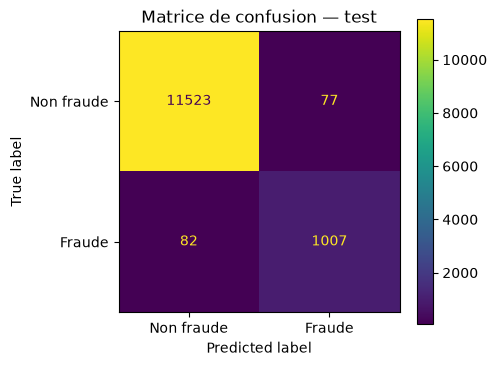

In [9]:
proba_test = modele.predict_proba(X_test)[:, 1]
pred_test = (proba_test >= seuil).astype(int)

metrics = {
    "recall": float(recall_score(y_test, pred_test)),
    "precision": float(precision_score(y_test, pred_test, zero_division=0)),
    "f1": float(f1_score(y_test, pred_test, zero_division=0)),
    "pr_auc": float(average_precision_score(y_test, proba_test)),
    "roc_auc": float(roc_auc_score(y_test, proba_test)),
    "seuil": float(seuil),
    "pct_alertes": float((pred_test == 1).mean() * 100),
    "n_alertes_test": int((pred_test == 1).sum()),
    "n_test": int(len(y_test)),
}

print("=" * 55)
print(f"VERSION {VERSION.upper()} | rappel_cible = {RAPPEL_CIBLE}")
print("=" * 55)
print(f"Seuil d'alerte    : {metrics['seuil']:.4f}")
print(f"Recall (test)     : {metrics['recall']:.4f}")
print(f"Precision (test)  : {metrics['precision']:.4f}")
print(f"F1                : {metrics['f1']:.4f}")
print(f"ROC-AUC           : {metrics['roc_auc']:.4f}")
print(f"PR-AUC            : {metrics['pr_auc']:.4f}")
print(f"Nb alertes (test) : {metrics['n_alertes_test']} / {metrics['n_test']} ({metrics['pct_alertes']:.1f}%)")
print()
print(classification_report(y_test, pred_test, target_names=["Non fraude", "Fraude"]))

fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(
    y_test, pred_test, display_labels=["Non fraude", "Fraude"], ax=ax
)
plt.title("Matrice de confusion — test")
plt.tight_layout()
plt.savefig(REPORTS / "cm_v1_test.png", dpi=120)
plt.show()

for k, v in metrics.items():
    mlflow.log_metric(k if k != "seuil" else "seuil_test", v)

In [10]:
if TYPE_COL and TYPE_COL in test_df.columns:
    df_t = X_test.copy()
    df_t["y_true"] = y_test.values
    df_t["y_pred"] = pred_test
    df_t[TYPE_COL] = test_df.loc[X_test.index, TYPE_COL].values

    print("Recall par type (seuil d'alerte) :")
    types = [
        "SURFACTURATION", "LIGNES_NON_PRESCRITES", "ORDONNANCE_EXPIREE",
        "QUANTITE_EXCESSIVE", "PRESTATAIRE_RADIE", "DOUBLON", "UPCODING",
        "SUBSTITUTION_PRODUIT", "SURCONSOMMATION", "SOINS_JOUR_FERME",
        "FRACTIONNEMENT", "ACTE_FICTIF", "HORS_COUVERTURE", "INCOHERENCE_PROFIL",
    ]
    for t in types:
        mask = df_t[TYPE_COL] == t
        if mask.sum() == 0:
            continue
        r = recall_score(df_t.loc[mask, "y_true"], df_t.loc[mask, "y_pred"], zero_division=0)
        print(f"  {t:30s} n={mask.sum():4d}  recall={r:.2%}")

Recall par type (seuil d'alerte) :
  SURFACTURATION                 n= 206  recall=100.00%
  LIGNES_NON_PRESCRITES          n= 113  recall=100.00%
  ORDONNANCE_EXPIREE             n=  85  recall=100.00%
  QUANTITE_EXCESSIVE             n=  76  recall=100.00%
  PRESTATAIRE_RADIE              n=  75  recall=98.67%
  DOUBLON                        n= 138  recall=76.09%
  UPCODING                       n= 104  recall=80.77%
  SUBSTITUTION_PRODUIT           n=  54  recall=100.00%
  SURCONSOMMATION                n=  40  recall=97.50%
  SOINS_JOUR_FERME               n=  30  recall=100.00%
  FRACTIONNEMENT                 n=  47  recall=93.62%
  ACTE_FICTIF                    n=  60  recall=90.00%
  HORS_COUVERTURE                n=  17  recall=100.00%
  INCOHERENCE_PROFIL             n=  44  recall=59.09%


## 8 — Comparaison XGBoost vs LightGBM vs HGB

Justifie le choix XGBoost (CDC : XGBoost/LightGBM).

In [11]:
from sklearn.ensemble import HistGradientBoostingClassifier

comparaison = [{
    "modele": "XGBoost (optimisé)",
    "seuil": metrics["seuil"],
    "recall": metrics["recall"],
    "precision": metrics["precision"],
    "pr_auc": metrics["pr_auc"],
    "roc_auc": metrics["roc_auc"],
}]

try:
    from lightgbm import LGBMClassifier
    pipe_lgb = Pipeline([
        ("preprocess", preprocess),
        ("clf", LGBMClassifier(
            n_estimators=200, max_depth=4, learning_rate=0.08,
            scale_pos_weight=spw, random_state=SEED, n_jobs=-1, verbose=-1,
        )),
    ])
    pipe_lgb.fit(X_train, y_train)
    p_va = pipe_lgb.predict_proba(X_val)[:, 1]
    s_lgb = seuil_rappel(y_val, p_va, RAPPEL_CIBLE)
    p_te = pipe_lgb.predict_proba(X_test)[:, 1]
    pred_lgb = (p_te >= s_lgb).astype(int)
    comparaison.append({
        "modele": "LightGBM",
        "seuil": round(s_lgb, 4),
        "recall": round(recall_score(y_test, pred_lgb), 4),
        "precision": round(precision_score(y_test, pred_lgb, zero_division=0), 4),
        "pr_auc": round(average_precision_score(y_test, p_te), 4),
        "roc_auc": round(roc_auc_score(y_test, p_te), 4),
    })
except ImportError:
    print("LightGBM non installé : pip install lightgbm")

pipe_hgb = Pipeline([
    ("preprocess", preprocess),
    ("clf", HistGradientBoostingClassifier(
        max_iter=200, learning_rate=0.08, class_weight="balanced", random_state=SEED,
    )),
])
pipe_hgb.fit(X_train, y_train)
p_va = pipe_hgb.predict_proba(X_val)[:, 1]
s_hgb = seuil_rappel(y_val, p_va, RAPPEL_CIBLE)
p_te = pipe_hgb.predict_proba(X_test)[:, 1]
pred_hgb = (p_te >= s_hgb).astype(int)
comparaison.append({
    "modele": "HGB (baseline)",
    "seuil": round(s_hgb, 4),
    "recall": round(recall_score(y_test, pred_hgb), 4),
    "precision": round(precision_score(y_test, pred_hgb, zero_division=0), 4),
    "pr_auc": round(average_precision_score(y_test, p_te), 4),
    "roc_auc": round(roc_auc_score(y_test, p_te), 4),
})

df_cmp = pd.DataFrame(comparaison)
display(df_cmp)
print("→ Modèle retenu en production : XGBoost (optimisé)")
df_cmp.to_csv(REPORTS / "comparaison_modeles_v1.csv", index=False)

,modele,seuil,recall,precision,pr_auc,roc_auc
0,XGBoost (optimisé),0.715577,0.924702,0.928967,0.972053,0.992699
1,LightGBM,0.491400,0.944000,0.775300,0.952200,0.987900
2,HGB (baseline),0.727700,0.922900,0.922900,0.970800,0.991200


→ Modèle retenu en production : XGBoost (optimisé)


## 9 — SHAP (CDC Module 3)

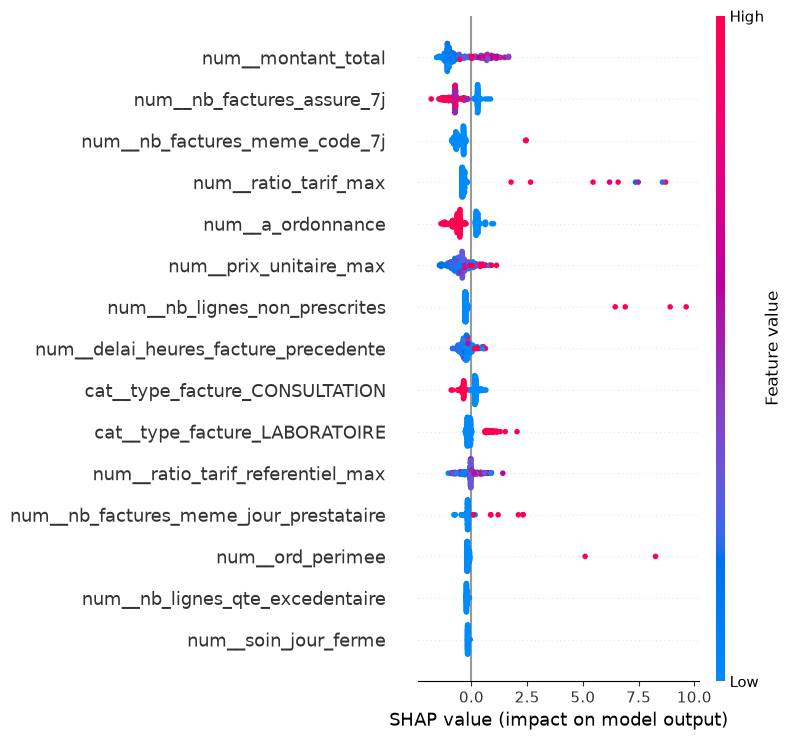

✓ e:\predicare\reports\shap_summary_v1.png

Exemple facture fraude détectée :
  Score=0.9994 | Seuil=0.7156 | OUI — à vérifier par un gestionnaire
    num__ord_perimee                         +8.2608  ↑ risque
    num__nb_factures_assure_7j               +0.8578  ↑ risque
    num__montant_total                       -0.5355  ↓ risque
    cat__type_facture_PHARMACIE              +0.4584  ↑ risque
    num__nb_factures_meme_code_7j            -0.4318  ↓ risque


In [12]:
try:
    import shap

    pre = modele.named_steps["preprocess"]
    clf = modele.named_steps["classifier"]
    X_sample = X_test.iloc[: min(300, len(X_test))]
    X_trans = pre.transform(X_sample)
    try:
        feat_names = list(pre.get_feature_names_out())
    except Exception:
        feat_names = [f"f{i}" for i in range(X_trans.shape[1])]

    explainer = shap.TreeExplainer(clf)
    shap_values = explainer.shap_values(X_trans)

    plt.figure()
    shap.summary_plot(shap_values, X_trans, feature_names=feat_names, max_display=15, show=False)
    plt.tight_layout()
    plt.savefig(REPORTS / "shap_summary_v1.png", dpi=120, bbox_inches="tight")
    plt.show()
    print("✓", REPORTS / "shap_summary_v1.png")

    def expliquer_facture(row_dict, top_n=10):
        df = pd.DataFrame([row_dict])[FEATURES]
        proba = float(modele.predict_proba(df)[0, 1])
        alerte = proba >= seuil
        Xt = pre.transform(df)
        sv = explainer.shap_values(Xt)
        if isinstance(sv, list):
            sv = sv[1]
        sv = np.asarray(sv).ravel()
        order = np.argsort(-np.abs(sv))[:top_n]
        contrib = [
            {"variable": str(feat_names[i]), "shap": float(sv[i]),
             "sens": "↑ risque" if sv[i] > 0 else "↓ risque"}
            for i in order
        ]
        return {
            "score": proba, "seuil": float(seuil), "alerte": alerte,
            "message": "OUI — à vérifier par un gestionnaire" if alerte else "NON",
            "shap_top": contrib,
        }

    idx_ok = np.where((pred_test == 1) & (y_test.values == 1))[0]
    if len(idx_ok):
        ex = expliquer_facture(X_test.iloc[int(idx_ok[0])].to_dict())
        print("\nExemple facture fraude détectée :")
        print(f"  Score={ex['score']:.4f} | Seuil={ex['seuil']:.4f} | {ex['message']}")
        for c in ex["shap_top"][:5]:
            print(f"    {c['variable']:40s} {c['shap']:+.4f}  {c['sens']}")

except ImportError:
    print("pip install shap")
    def expliquer_facture(row_dict, top_n=10):
        df = pd.DataFrame([row_dict])[FEATURES]
        proba = float(modele.predict_proba(df)[0, 1])
        return {"score": proba, "seuil": float(seuil),
                "alerte": proba >= seuil,
                "message": "OUI" if proba >= seuil else "NON", "shap_top": []}

## 10 — Sauvegarde models/v1 + fin run MLflow

Artifacts : model.joblib, metadata.json (**seuil_alerte**), schema_inference.json.

In [13]:
joblib.dump(modele, MODELS / "model.joblib")
print("✓", MODELS / "model.joblib")

meta = {
    "version": VERSION,
    "modele": "xgboost",
    "date": datetime.now().isoformat(timespec="seconds"),
    "features": FEATURES,
    "n_variables": len(FEATURES),
    "cat_cols": CAT_COLS,
    "num_cols": NUM_COLS,
    "seuil_alerte": float(seuil),
    "rappel_cible": float(RAPPEL_CIBLE),
    "scale_pos_weight": float(spw),
    "desequilibre": "scale_pos_weight",
    "split_mode": split_mode,
    "hyperparametres": {
        k.replace("classifier__", ""): (v.item() if hasattr(v, "item") else v)
        for k, v in search.best_params_.items()
    },
    "resultats_test": metrics,
    "mlflow_run_id": mlflow.active_run().info.run_id if mlflow.active_run() else None,
    "note": (
        "seuil_alerte = score min pour alerte gestionnaire. "
        "Configurable en prod via admin / .env sans réentraîner. "
        "RAPPEL_CIBLE sert uniquement au calibrage pendant l'entraînement."
    ),
}

with open(MODELS / "metadata.json", "w", encoding="utf-8") as f:
    json.dump(meta, f, indent=2, ensure_ascii=False)
print("✓", MODELS / "metadata.json")

schema = {
    "version": VERSION,
    "features_ordonnees": FEATURES,
    "types": {c: ("categorical" if c in CAT_COLS else "numeric") for c in FEATURES},
    "seuil_alerte": float(seuil),
    "rappel_cible_entrainement": float(RAPPEL_CIBLE),
}
with open(MODELS / "schema_inference.json", "w", encoding="utf-8") as f:
    json.dump(schema, f, indent=2, ensure_ascii=False)
print("✓", MODELS / "schema_inference.json")

if mlflow.active_run() is not None:
    mlflow.log_artifact(str(MODELS / "model.joblib"))
    mlflow.log_artifact(str(MODELS / "metadata.json"))
    mlflow.log_artifact(str(MODELS / "schema_inference.json"))
    for name in ["cm_v1_test.png", "comparaison_modeles_v1.csv", "shap_summary_v1.png"]:
        p = REPORTS / name
        if p.exists():
            mlflow.log_artifact(str(p))
    mlflow.end_run()
    print("✓ Run MLflow terminé")

print(f"\n>>> Seuil d'alerte à utiliser en prod : {seuil:.4f}")
print(">>> (modifiable ensuite via admin / .env — CDC Configurable)")
print(">>> UI : mlflow ui  →  http://127.0.0.1:5000")

✓ e:\predicare\models\v1\model.joblib
✓ e:\predicare\models\v1\metadata.json
✓ e:\predicare\models\v1\schema_inference.json
✓ Run MLflow terminé

>>> Seuil d'alerte à utiliser en prod : 0.7156
>>> (modifiable ensuite via admin / .env — CDC Configurable)
>>> UI : mlflow ui  →  http://127.0.0.1:5000


## 11 — (Optionnel) Plusieurs rappels cibles dans MLflow

Chaque RAPPEL_CIBLE = 1 run → colonnes rappel_cible, seuil_alerte, recall, precision.

In [14]:
LANCER_COMPARAISON_RAPPELS = False  # True pour 0.90 / 0.92 / 0.95

if LANCER_COMPARAISON_RAPPELS:
    for rc in [0.90, 0.92, 0.95]:
        with mlflow.start_run(run_name=f"v1_seuil_rappel_{rc}"):
            mlflow.log_param("version", VERSION)
            mlflow.log_param("model_type", "xgboost")
            mlflow.log_param("rappel_cible", rc)
            s = seuil_rappel(y_val, modele.predict_proba(X_val)[:, 1], rc)
            pred = (modele.predict_proba(X_test)[:, 1] >= s).astype(int)
            proba = modele.predict_proba(X_test)[:, 1]
            mlflow.log_metric("seuil_alerte", float(s))
            mlflow.log_metric("recall", float(recall_score(y_test, pred)))
            mlflow.log_metric("precision", float(precision_score(y_test, pred, zero_division=0)))
            mlflow.log_metric("pr_auc", float(average_precision_score(y_test, proba)))
            print(f"rappel_cible={rc} → seuil={s:.4f}  recall={recall_score(y_test, pred):.3f}  "
                  f"prec={precision_score(y_test, pred, zero_division=0):.3f}")
    print("Comparaison rappels terminée → rafraîchir MLflow UI")
else:
    print("Comparaison multi-rappels désactivée (LANCER_COMPARAISON_RAPPELS = False)")

Comparaison multi-rappels désactivée (LANCER_COMPARAISON_RAPPELS = False)


## 12 — Test d'inférence

In [ ]:
facture_test = {
    "ord_perimee": 0, "nb_lignes_non_prescrites": 0, "nb_lignes_qte_excedentaire": 0,
    "presta_apres_fin_convention": 0, "ord_apres_soin": 0, "ord_autre_assure": 0,
    "soin_avant_adhesion": 0, "soin_apres_radiation": 0, "ratio_tarif_max": 1.02,
    "prix_unitaire_max": 15000, "montant_total": 28000, "repetition_potentielle": 0,
    "nb_factures_meme_jour_prestataire": 1, "type_facture": "PHARMACIE", "a_ordonnance": 1,
    "nb_factures_assure_7j": 1, "nb_factures_meme_code_7j": 1,
    "delai_heures_facture_precedente": 720.0, "montant_identique_48h": 0,
    "majoration_horaire_incoherente": 0, "ratio_tarif_referentiel_max": 1.0,
    "upcoding_specialite_suspect": 0, "soin_jour_ferme": 0,
}

out = expliquer_facture(facture_test)
print("Score        :", round(out["score"], 4))
print("Seuil alerte :", round(out["seuil"], 4))
print("Alerte       :", out["message"])
if out.get("shap_top"):
    print("Top SHAP :")
    for c in out["shap_top"][:5]:
        print(f"  {c['variable']:40s} {c['shap']:+.4f}  {c['sens']}")

---

### Récap MLflow

```powershell
cd E:\\predicare
mlflow ui
```

http://127.0.0.1:5000 → **PrediCare-fraude**

| Colonne UI | Signification |
|------------|---------------|
| `rappel_cible` | Objectif recall d'entraînement |
| `seuil` / `seuil_alerte` | Score min pour alerter (prod) |
| `xgb_*` | Hyperparams |
| `recall`, `precision`, `pr_auc` | Métriques test |

Changer `RAPPEL_CIBLE` et relancer = **nouveau run** comparable.